In [1]:
from micrograd.engine import Value
from micrograd.nn import MLP

In [21]:
# create a simple nn
# test on function y = x**3 - 2*x**2 + 3x
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-1, 1, 50)

In [22]:
# ✅ Each xi is a plain Python float
X = [Value(float(xi)) for xi in x.flatten()]
y_vals = [Value(float(yi)) for yi in (x.flatten() ** 3)]

In [23]:
# data points are x, y
# lets create a 2 layer nn
model  = MLP(1, [30, 30, 1])

In [24]:
# training loop
for i in range(100):

    # forward pass
    preds = [model([xi]) for xi in X]

    # calculate loss
    loss = sum((yi - pred_i[0]) ** 2 for yi, pred_i in zip(y_vals, preds)) * (
        1 / len(preds)
    )
    if i % 50 == 0:
        print(loss.value)

    # backward pass
    loss.backward()

    # step
    for p in model.parameters():
        h = 0.05 if i < 70 else 0.01
        p.value -= h * p.grad

    # zero grad
    model.zero_grad()

1.802789327588743
0.0066346909287809406


In [27]:
test_x = np.linspace(-0.5, 0.5, 20)
X_test = [Value(float(xi)) for xi in test_x.flatten()]
y_preds = [model([xi]) for xi in X_test]

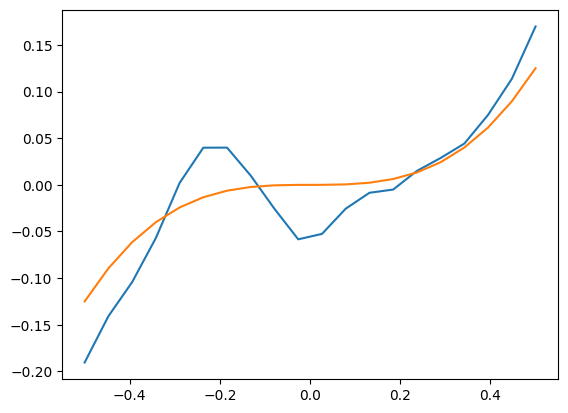

In [30]:
plt.plot(test_x, [yi[0].value for yi in y_preds])
plt.plot(test_x, test_x ** 3)